# 把科学观测写成 token，交给同一个 nanoGPT

这本 Notebook 带你把一个科学方向从头走一遍，再看怎样让程序自己改进模型。

| 节 | 做什么 | 默认方向（扩散场）在 CPU 上的用时 |
|---|---|---|
| 0 | 选方向、装依赖 | 依赖已装好时几秒 |
| 1 | 看数据：几条样本和标签分布 | 几秒 |
| 2 | 预处理：切成 token、标准化 | 几秒 |
| 3 | 搭模型：编码器、两层 nanoGPT、读出头 | 几秒 |
| 4 | 预训练：只用无标签数据，预测下一个 token | 10 到 30 秒 |
| 5 | 下游训练：用 32 个标签学会回答问题 | 几秒 |
| 6 | 评测：留出样本上的误差，和两条基线比 | 几秒 |
| 7 | 自动研究：让程序自己提改动、跑实验；再把搜索经验带到没见过的方向 | 看存档几秒；现场跑 2 轮 1 到 4 分钟 |
| 8 | 星流轨道拟合：调参智能体怎样积累经验 | 约 10 秒 |

每一节开头的大写变量都可以改，改完从那一格往下重新运行。十一个方向用的是同一份代码，只在第 0 节换 `FIELD`。每张图上方加粗的一句话是这张图的结论，由当前的数字生成，换方向会跟着变。

可选方向：spectrum（光谱）、protein（蛋白质）、dna、rna、smiles（小分子）、crystal（晶体）、structure3d（三维结构）、weather（天气场）、field（扩散场）、image（天文图像）、text（文本）。每个方向的专业定义、单位和数据出处见仓库的 data/eleven/SOURCES.md。

## 0. 选方向，装依赖

这一格检查 PyTorch、NumPy、scikit-learn 和 Matplotlib，缺哪个装哪个。在仓库外单独打开这本 Notebook 时，它会先把仓库克隆到当前目录。全程只用 CPU。

In [1]:
FIELD = "field"            # 换方向只改这里
SEED = 53                  # 随机种子：决定抽哪 32 个标签、模型的初始权重
N_LABELS = 32              # 下游用多少个带标签的对象。文档里的数字都是 32
THREADS = 2                # CPU 线程数。想复现文档里的数字就保持 2

import importlib.util
import subprocess
import sys
import time
from pathlib import Path

if importlib.util.find_spec("torch") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torch",
                           "--index-url", "https://download.pytorch.org/whl/cpu"])
missing = [pip for module, pip in (("numpy", "numpy"), ("sklearn", "scikit-learn"), ("matplotlib", "matplotlib"))
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

here = Path.cwd().resolve()
root = next((p for p in [here, *here.parents] if (p / "nanoscigpt" / "tasks" / "eleven.py").exists()), None)
if root is None:
    subprocess.check_call(["git", "clone", "--depth", "1", "https://github.com/Yu-Yang-Li/nanoSciGPT.git"])
    root = here / "nanoSciGPT"
sys.path.insert(0, str(root))

import numpy as np
import torch
torch.set_num_threads(THREADS)
from nanoscigpt.tasks import eleven, eleven_plots as plots
eleven.N_LABELS = N_LABELS

font = plots.use_chinese_font()
if font is None:
    print("没有找到中文字体，自动下载也没成功，图里的中文会显示成方框。Linux 上可以运行：sudo apt install fonts-noto-cjk")

spec = eleven.FIELDS[FIELD]
print(f"{spec['name']}（{spec['data']}数据）：{spec['question']}。标签：{spec['label']}")
print(f"一个 token = {spec['token']}")
READOUT_NAMES = {"probe": "冻结主干 + 线性头", "finetune": "全参数微调", "probe+surprise": "冻结主干 + 线性头，另加模型的意外程度"}
print(f"下游任务：{spec['task']}；读出：{READOUT_NAMES[spec['readout']]}；"
      f"预训练：{'每档 1,600 步' if spec['budget'] == 'fixed' else '每个对象平均 32 遍'}")

扩散场（模拟数据）：看几帧画面，推测扩散得多快。标签：模拟设定
一个 token = 4 个相邻位置连续四帧
下游任务：扩散系数（log10）；读出：全参数微调；预训练：每个对象平均 32 遍


## 1. 看数据

动手训练之前，先看数据长什么样。每个方向有三份数据，用途分开：

- **无标签对象**：12,800 个，只有输入，没有答案。预训练只用这一份。
- **标签池**：一两百个带答案的对象，每次从里面抽 `N_LABELS` 个（默认 32）来训练下游。
- **留出组 A**：几百个带答案的对象，不参与任何训练，只用来算最后的误差。

下面画出留出组里标签偏低、居中、偏高的三条样本，以及标签的分布。先自己看一眼：凭肉眼能不能从输入猜出标签的高低？

无标签对象：patches (12800, 16, 16)


标签池：patches (256, 16, 16)
留出组 A：patches (480, 16, 16)


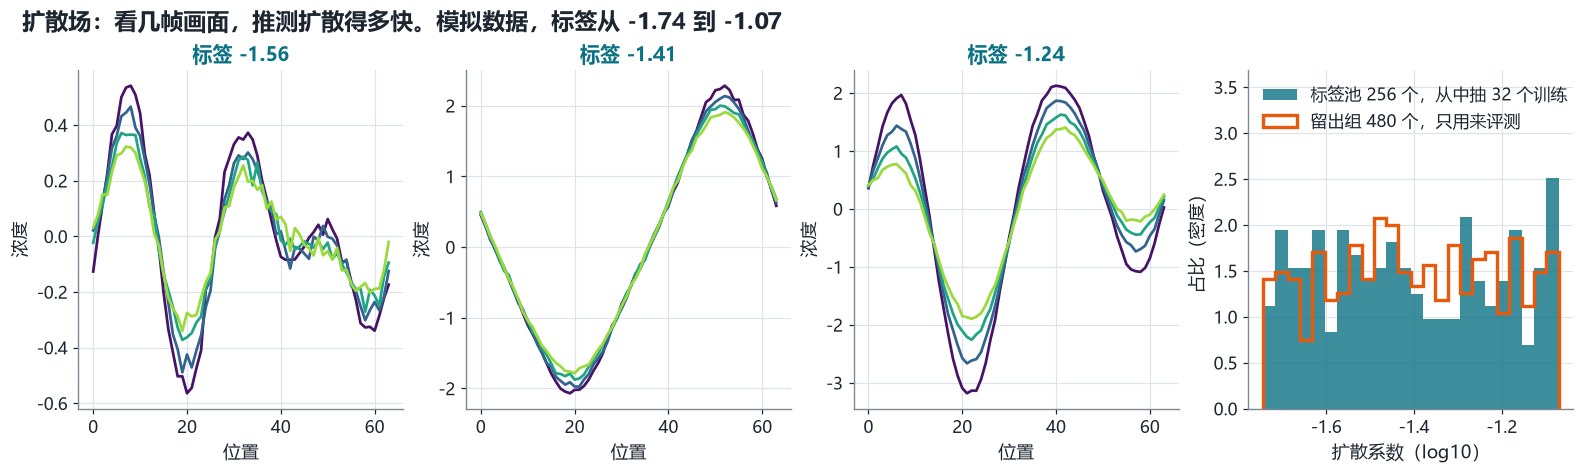

In [2]:
N_EXAMPLES = 3             # 画几条样本

raw_parts, raw_task = eleven.load(FIELD)
for name, (inputs, _) in {"无标签对象": raw_parts["unlabeled"], "标签池": raw_task["pool"], "留出组 A": raw_task["A"]}.items():
    print(f"{name}：" + "，".join(f"{key} {tuple(values.shape)}" for key, values in inputs.items()))
plots.show_samples(FIELD, raw_task, N_EXAMPLES)

## 2. 预处理：把一个对象切成 token

语言模型读的是一串 token。这一步把上面的对象写成这样一串：左图是原始对象和 token 的边界，右图是模型实际读到的内容。

- 符号类输入（蛋白质、DNA、RNA、小分子、文本）：一个符号一个 token，查词表变成编号。
- 数值类输入（光谱、图像、各种场、距离矩阵）：相邻的几个数组成一个 token。
- 晶体：晶格矩阵是第一个 token，之后每个原子一个 token。

改 `ROW` 可以换一条样本看。

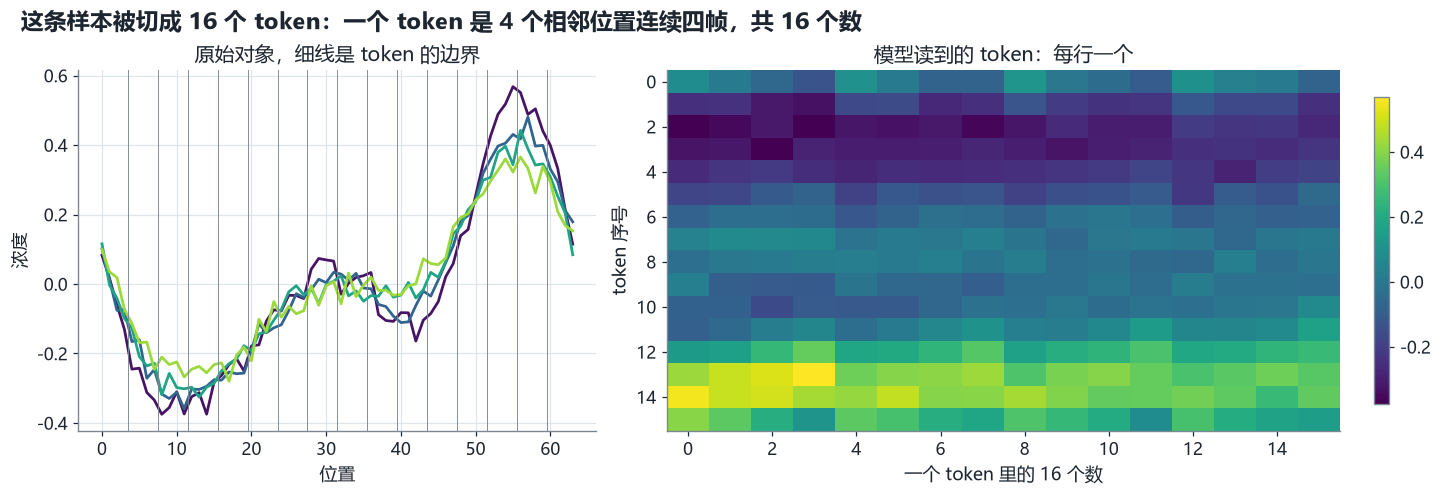

16 个 token，每个 token 是 16 个数
token 1： [0.083, 0.017, -0.06, -0.131, 0.101, 0.012, -0.076, -0.073] ...
token 2： [-0.245, -0.242, -0.312, -0.334, -0.166, -0.16, -0.272, -0.246] ...
token 3： [-0.375, -0.356, -0.31, -0.374, -0.317, -0.329, -0.312, -0.359] ...
这条样本的下游标签： -1.3254


In [3]:
ROW = 0                    # 看留出组里的第几条样本

plots.show_tokens(FIELD, raw_task, ROW)
eleven.show_tokens(FIELD, {name: values[ROW] for name, values in raw_task["A"][0].items()})
print("这条样本的下游标签：", round(float(raw_task["A"][1][ROW]), 4))

数值类输入还要做标准化：减去均值、除以标准差，让不同位置的数在同一个量级上。均值和标准差只从抽中的那些带标签的训练对象上算，评测数据不参与，这样留出组的信息不会漏进训练。符号类输入不需要这一步，下面改为画符号的出现次数。

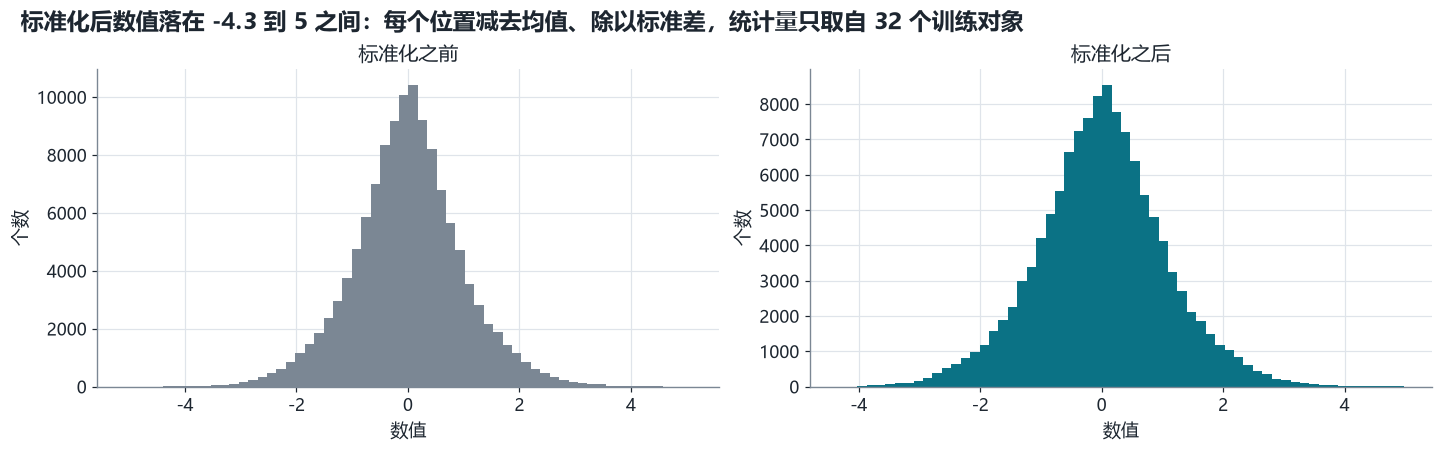

In [4]:
parts, task = eleven.normalize(FIELD, raw_parts, raw_task, SEED)
plots.show_normalization(FIELD, raw_task, task)

## 3. 搭模型

模型分三段：

1. **编码器**：把每个 token 变成一个 32 维的向量。十一个方向只有这一段不同，共三种（符号、数值块、晶胞）。
2. **两层 nanoGPT**：十一个方向结构完全相同。每个位置只能看到它前面的 token。
3. **读出头**：一个线性层，把整条序列的表示变成一个数，也就是下游任务的答案。

下面打印编码器的结构，再画出每一段有多少参数。把 `COMPARE_WITH` 换成别的方向，可以看到两个方向只有编码器和位置编码的参数个数不同。

PatchEncoder(
  (project): Linear(in_features=16, out_features=32, bias=True)
  (to_patch): Linear(in_features=32, out_features=16, bias=True)
)
主干：2 层，每层 2 个注意力头，向量 32 维，序列最长 16 个 token


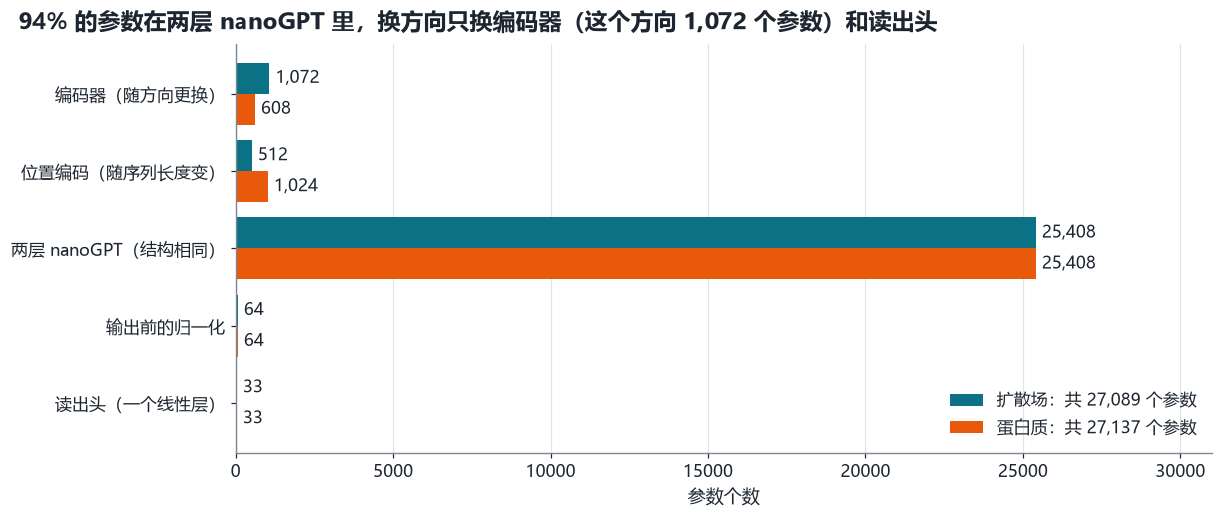

In [5]:
COMPARE_WITH = "protein"   # 拿哪个方向来对比参数个数

model = eleven.network(FIELD)
print(model.encoder)
print(f"主干：{len(model.blocks)} 层，每层 {model.blocks[0].attn.n_head} 个注意力头，向量 {model.blocks[0].attn.n_embd} 维，"
      f"序列最长 {model.wpe.num_embeddings} 个 token")
plots.show_model([FIELD] if COMPARE_WITH == FIELD else [FIELD, COMPARE_WITH])

## 4. 预训练：只用无标签数据

预训练的题目是“根据前面的 token 预测下一个 token”，答案就在数据自己里面，不需要任何标签。这里用不同数量的无标签对象各训练一次，看数据多了以后模型是不是学得更好。

- 曲线：训练过程中每一批数据上的损失。
- 圆点：训练结束后，在留出样本（没参加训练）上的损失。圆点比曲线末端高很多，说明模型只是记住了训练数据。

把 12800 加进 `SIZES` 可以跑到最大档，用时大约是现在的四倍。

   200 个无标签对象：更新   100 次，留出样本上的损失 0.0647，用时 2 秒


   800 个无标签对象：更新   400 次，留出样本上的损失 0.0146，用时 3 秒


  3200 个无标签对象：更新  1600 次，留出样本上的损失 0.0073，用时 16 秒


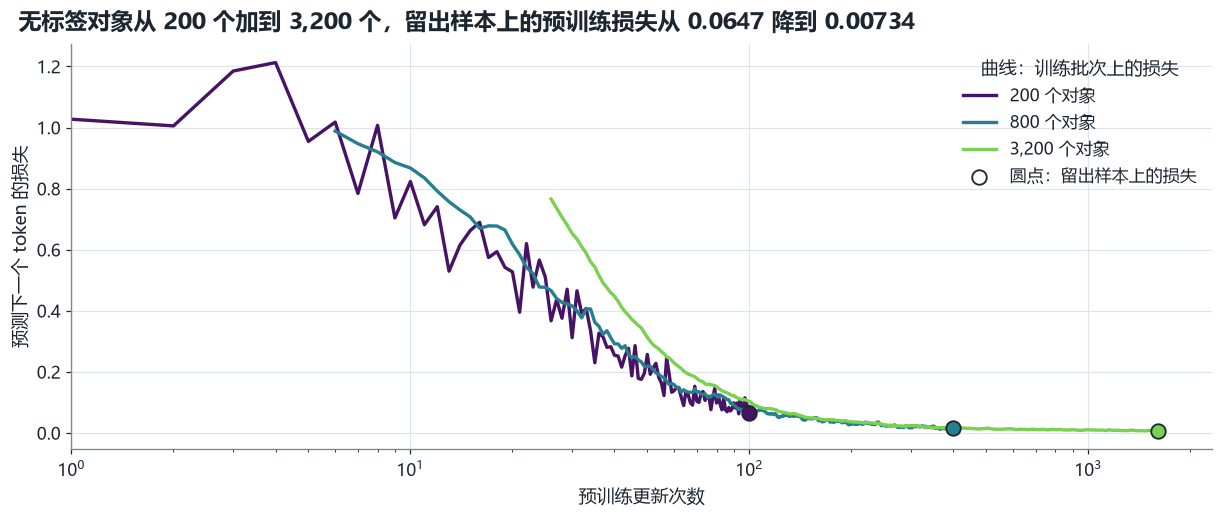

In [6]:
SIZES = [200, 800, 3200]   # 预训练用的无标签对象数，可以加上 12800

models = {0: eleven.pretrain(FIELD, parts, 0, SEED)}   # 0 = 不预训练，作对照
curves, pretrain_loss = {}, {}
for size in SIZES:
    start = time.perf_counter()
    curves[size] = []
    models[size] = eleven.pretrain(FIELD, parts, size, SEED, curve=curves[size])
    pretrain_loss[size] = eleven.heldout_loss(models[size], parts["A"][0])
    print(f"{size:>6} 个无标签对象：更新 {len(curves[size]):>5} 次，留出样本上的损失 {pretrain_loss[size]:.4f}，用时 {time.perf_counter() - start:.0f} 秒")
plots.show_training(curves, pretrain_loss)

## 5. 下游训练：用少量标签学会回答问题

现在才用到标签。从标签池里抽 `N_LABELS` 个对象，接在预训练好的模型后面训练读出。读出方式有三种，每个方向有自己的默认值：

- **冻结主干 + 线性头**：主干不动，只训练最后那个线性层。
- **全参数微调**：所有权重一起更新 200 步。
- **冻结主干 + 线性头，另加模型的意外程度**：只用于文本。除了表示，再给线性头两个数：模型逐个预测下一个字母时，平均有多意外、最意外的一处有多意外。拼写学得越熟的模型，碰到被换掉的字母越意外。

每个预训练规模各训练一次读出，再加一个“不预训练”的对照：同样的模型、同样的标签，只是主干没有预训练过。图里每个点是留出组的一个对象，越贴近对角线越好。

          不预训练：留出组 A 上的平均绝对误差 0.1692


    200 个对象预训练：留出组 A 上的平均绝对误差 0.1296


    800 个对象预训练：留出组 A 上的平均绝对误差 0.1242


   3200 个对象预训练：留出组 A 上的平均绝对误差 0.0935
         只猜平均值：0.1696


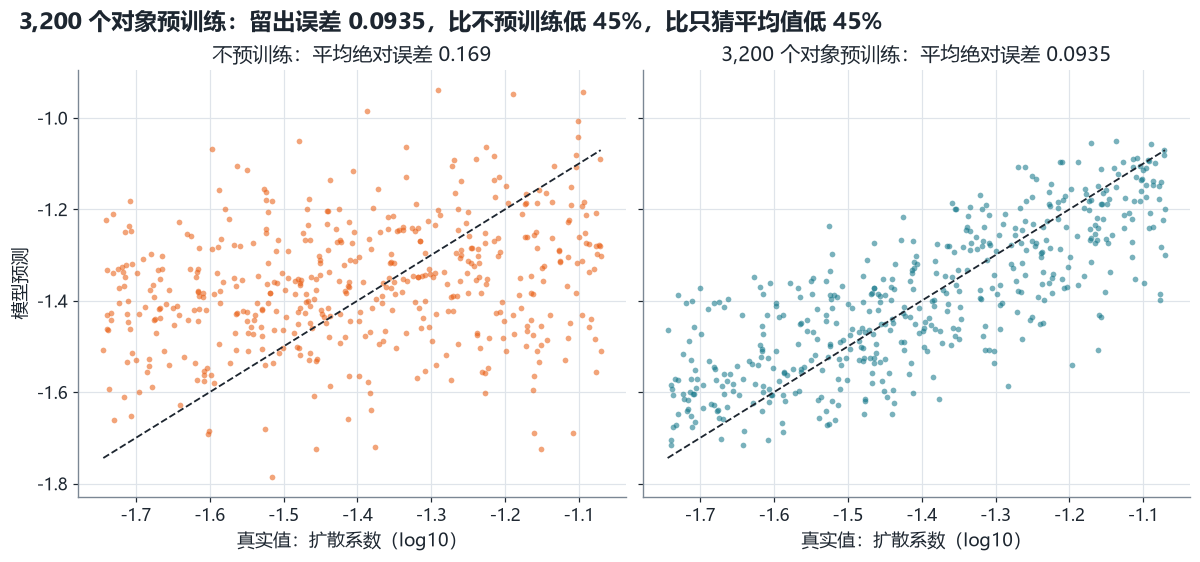

In [7]:
READOUT = spec["readout"]  # "probe"：冻结主干 + 线性头；"finetune"：全参数微调；"probe+surprise"：另加意外程度（文本）
COMPARE = (0, max(SIZES))  # 画哪两个模型的预测。0 是不预训练

downstream_error, predictions = {}, {}
for size, trained in models.items():
    predictions[size] = []
    downstream_error[size], guess_mean = eleven.downstream(FIELD, trained, task, SEED, predictions=predictions[size], readout=READOUT)
    name = "不预训练" if size == 0 else f"{size} 个对象预训练"
    print(f"{name:>14}：留出组 A 上的平均绝对误差 {downstream_error[size]:.4f}")
print(f"{'只猜平均值':>14}：{guess_mean:.4f}")
plots.show_predictions(task["A"][1], {("不预训练" if size == 0 else f"{size:,} 个对象预训练"): np.array(predictions[size]) for size in COMPARE},
                       guess_mean, spec["task"])

## 6. 评测

误差要和基线比才有意义。这里有两条基线：

- **只猜平均值**：不用任何模型，对每个对象都回答训练标签的平均值。比它还差，说明模型没学到东西。
- **不预训练**：检验预训练有没有帮上忙。

左图是下游误差随预训练数据量的变化，和两条基线画在一起。右图是预训练损失。要看的是两条曲线是不是随数据量一起下降，以及下游误差落在两条基线的哪一边。

这里只跑了一个种子、到 3,200 档，曲线会有起伏。五个种子、四档的结果见仓库的 docs/pretraining-scale/shared-checkpoints/README.md。

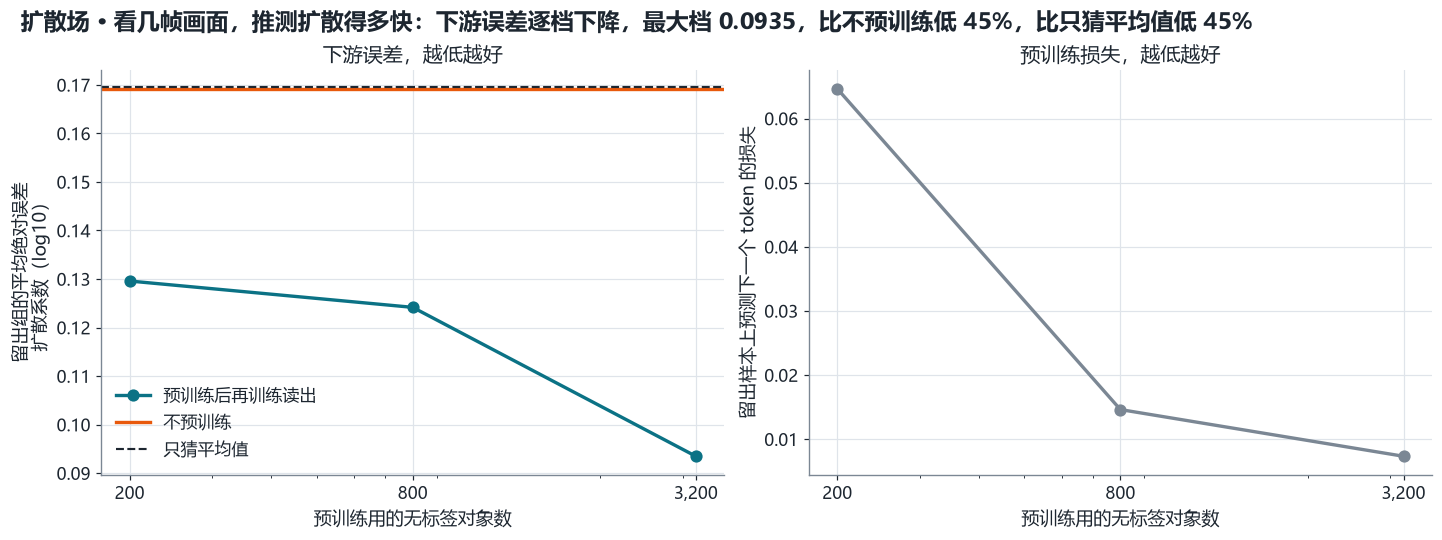

最好的一档是 3,200 个对象：误差 0.09347，比不预训练低 45%，比只猜平均值低 45%。


In [8]:
plots.show_scaling(pretrain_loss, downstream_error, guess_mean, f"{spec['name']} · {spec['question']}", spec["task"])
best = min(SIZES, key=downstream_error.get)
print(f"最好的一档是 {best:,} 个对象：误差 {downstream_error[best]:.4g}，"
      f"比不预训练{'低' if downstream_error[best] < downstream_error[0] else '高'} {abs(1 - downstream_error[best] / downstream_error[0]):.0%}，"
      f"比只猜平均值{'低' if downstream_error[best] < guess_mean else '高'} {abs(1 - downstream_error[best] / guess_mean):.0%}。")

## 7. 自动研究：让程序自己提改动、跑实验

前面每个设置都是人定的。这一节把“改设置、跑实验、看结果、再改”交给程序。十一个方向用同一套规则：

- **不能改**：两层 nanoGPT 主干。
- **可以改**：相邻两个 token 要不要并成一个（`merge`）、预训练的题目（预测下一个、隔一个预测、先遮住一部分再预测）、预训练步数和学习率、读出方式和它的步数、学习率、岭回归强度、表示的汇总方式。
- **怎么打分**：每个配置在开发集上评分。开发集是标签池里没被抽去训练的对象。留出组 A 只在搜索结束后用一次，评开发集上最好的那个配置。
- **两种提改动的办法**：DSK（一个大语言模型）读完此前每一轮的结果再提下一个配置；随机搜索在同样的范围里随便抽。两边轮数相同。

先看存档的结果：每个方向 DSK 和随机搜索各跑 2 到 4 次，每次 8 轮。跑不赢随机搜索的方向照实标出。

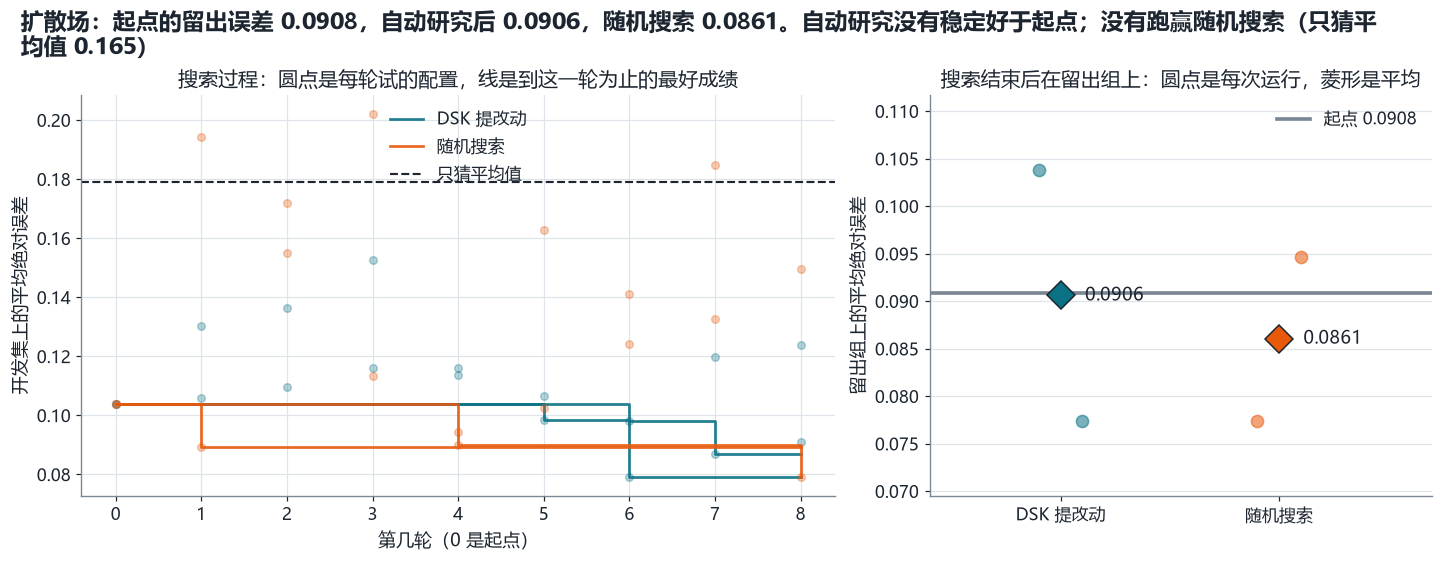

DSK 提改动 第 1 次：选中第 7 轮，留出误差 0.1038，相对起点改了 {"merge": 2, "objective": "masked", "pretrain_steps": 1600}
DSK 提改动 第 2 次：选中第 6 轮，留出误差 0.07743，相对起点改了 {"merge": 2, "finetune_steps": 400, "finetune_lr": 0.0003}
随机搜索 第 1 次：选中第 8 轮，留出误差 0.07743，相对起点改了 {"merge": 2, "finetune_steps": 400, "finetune_lr": 0.0003}
随机搜索 第 2 次：选中第 1 轮，留出误差 0.09468，相对起点改了 {"objective": "masked", "pretrain_lr": 0.003, "finetune_steps": 100, "pretrain_steps": 3200}
DSK 第 1 次运行每一轮的理由：
  第 1 轮，开发集误差 0.1059：起点使用 next 目标且预训练损失极低（0.00376），说明任务可能过于简单、表示学习不足；masked 目标通常能学到更丰富的扩散动力学表示。先切换到 masked 并采用中
  第 2 轮，开发集误差 0.1096：masked 0.3 与 next 的差距在种子波动内，但 masked 预训练损失更高、表示可能更丰富；下一步增加 mask 难度到 0.5 并提高预训练步数到 6400 以充分
  第 3 轮，开发集误差 0.1527：masked 0.3/0.5 与 next 的差距仍在种子波动内，且预训练损失偏高，说明当前 6400 步可能不足以让 masked 目标收敛；先降低 mask 难度回 0.3 并
  第 4 轮，开发集误差 0.1136：起点 next+finetune(0.1037) 仍是最佳；masked 目标未带来稳定改进，而降低预训练学习率显著变差(0.1527)。因此回到 next 目标，但把预训练步数减
  第 5 轮，开发集误差 0.0984：起点 next+finetune(0.1037) 仍最佳，且预训练损失极低说明任务过简；减少预训练步数到 3200 反而变差(0.11357)。下一步尝试 me

In [9]:
from autoresearch import common_search as search, search_plots

runs = [run for run in search.archived(FIELD) if run["method"] != "skill"]
search_plots.show_search(FIELD, runs)
for run in runs:
    if run["method"] == "model" and run["repeat"] == 1:
        print("DSK 第 1 次运行每一轮的理由：")
        for trial in run["trials"][1:]:
            print(f"  第 {trial['round']} 轮，开发集误差 {trial['dev']:.4f}：{trial['reason'][:90]}")

十一个方向放在一起看：

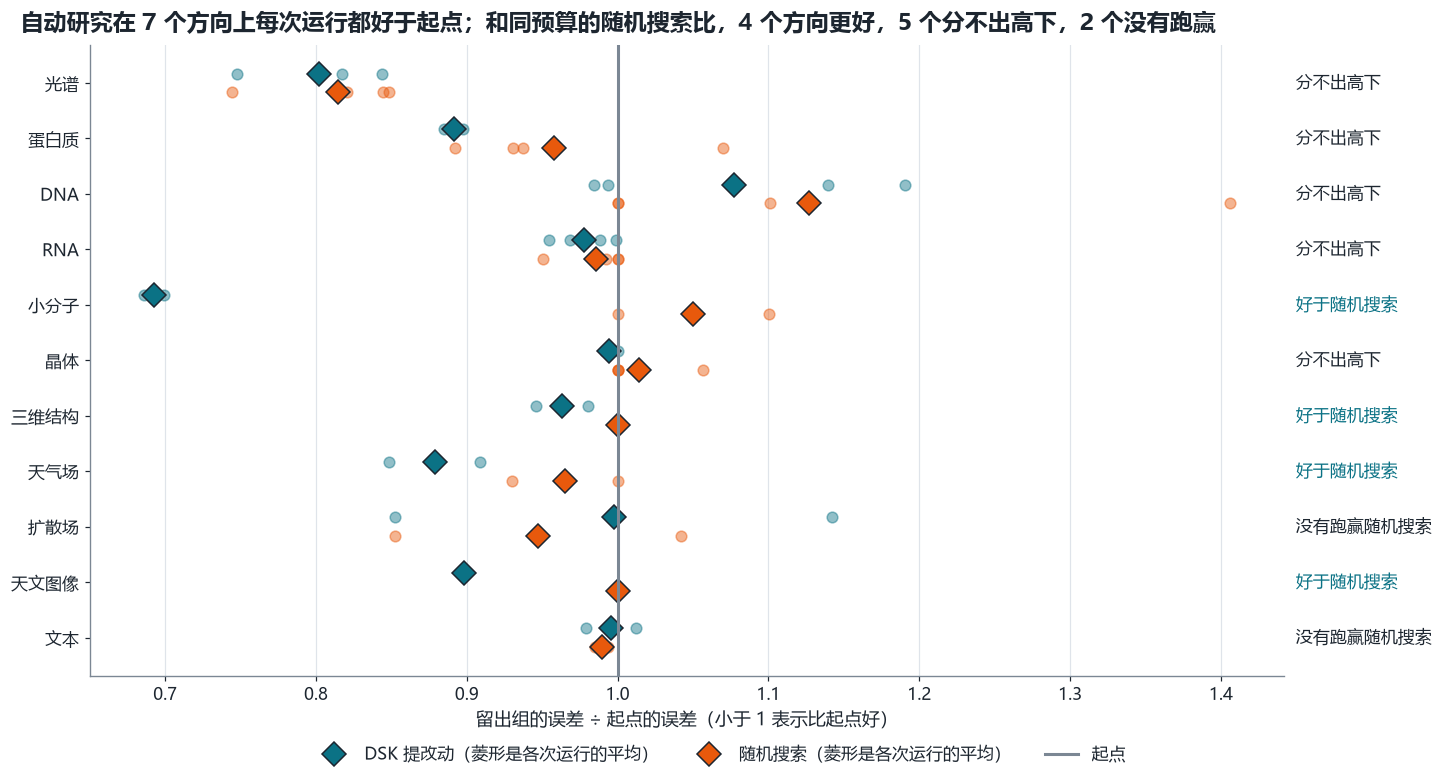

方向            起点       DSK      随机搜索      只猜均值  运行次数  结论
光谱        0.0652   0.05229    0.0531    0.3257     4      好于起点；和随机搜索分不出高下
蛋白质        6.287     5.606      6.02     10.83     4      好于起点；和随机搜索分不出高下
DNA        2.975     3.203     3.351     7.068     4      没有稳定好于起点；和随机搜索分不出高下
RNA       0.1555    0.1521    0.1533     0.161     4      好于起点；和随机搜索分不出高下
小分子       0.1147   0.07948    0.1205     0.228     2      好于起点；好于随机搜索
晶体        0.4673    0.4644    0.4739    0.5641     4      没有稳定好于起点；和随机搜索分不出高下
三维结构      0.8307       0.8    0.8307     2.859     2      好于起点；好于随机搜索
天气场       0.1242    0.1091    0.1199     0.164     2      好于起点；好于随机搜索
扩散场      0.09085    0.0906   0.08606     0.165     2      没有稳定好于起点；没有跑赢随机搜索
天文图像      0.4516    0.4056    0.4516     0.628     2      好于起点；好于随机搜索
文本         1.255      1.25     1.242      1.23     2      没有稳定好于起点；没有跑赢随机搜索


In [10]:
search_plots.show_all_fields()

下面现场跑一次。默认用随机搜索，不需要任何密钥。想让 DSK 来提改动，先在启动 Jupyter 之前设置环境变量 `SCNET_API_BASE`、`SCNET_API_KEY`、`SCNET_MODEL`，再把 `METHOD` 改成 "model"。密钥只从环境变量读，不要写进 Notebook。

默认只跑 2 轮、1 个种子，为的是几分钟内看完流程。这么少的轮数很可能找不到比起点更好的配置，结果的波动也比存档大。想认真搜索就把轮数和种子调到存档的设置，用时会长到几十分钟。运行记录存在仓库的 `out/` 目录下，同一格重新运行会接着上次的进度；换 `DEV_SEEDS` 之前请先删掉那里的记录。

field random-1 留出组 A：选中第 0 轮，误差 0.08663（起点 0.08663，只猜均值 0.16963）


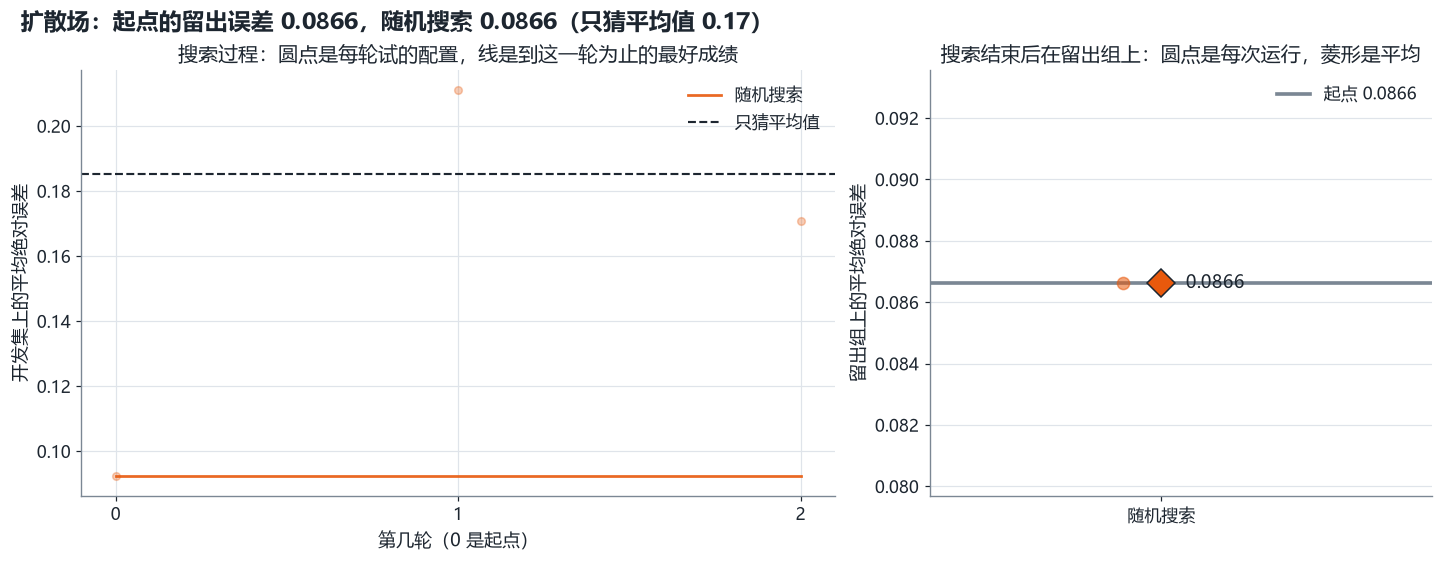

随机搜索 第 1 次：选中第 0 轮，留出误差 0.08663，相对起点改了 无


In [11]:
METHOD = "random"          # "random" 随机搜索；"model" 让 DSK 提改动（需要环境变量里有密钥）
ROUNDS = 2                 # 轮数。存档用的是 8
DEV_SEEDS = (53,)          # 每个配置用几个种子打分。存档用的是 (53, 71, 89)

journal = search.run(FIELD, METHOD, root / "out" / f"search-{N_LABELS}labels", rounds=ROUNDS, dev_seeds=DEV_SEEDS, confirm_seeds=DEV_SEEDS)
search_plots.show_search(FIELD, [journal])

### 7.1 把搜索经验带到没见过的方向

上面的搜索每个方向都从零开始，在一个方向上学到的东西带不到下一个方向。这一小节试着把它留下来：

1. 十一个方向分成 4 折，轮着留出。
2. 每一折，DSK 读其余方向的全部搜索记录，写成一份一千多字的搜索经验：哪类输入先试什么、哪些改动通常没用、8 轮怎么分配。
3. 经验锁定后，带到这一折留出的方向上搜索。提示里只多了这份经验，轮数、种子、打分方式都和之前一样。
4. 和不带经验的 DSK、同预算的随机搜索比。

留出哪几个方向、怎么判定“有用”，都在运行之前写定。左图按“此前的搜索有没有找到改进”把方向分成两组；右图看搜索得快不快。

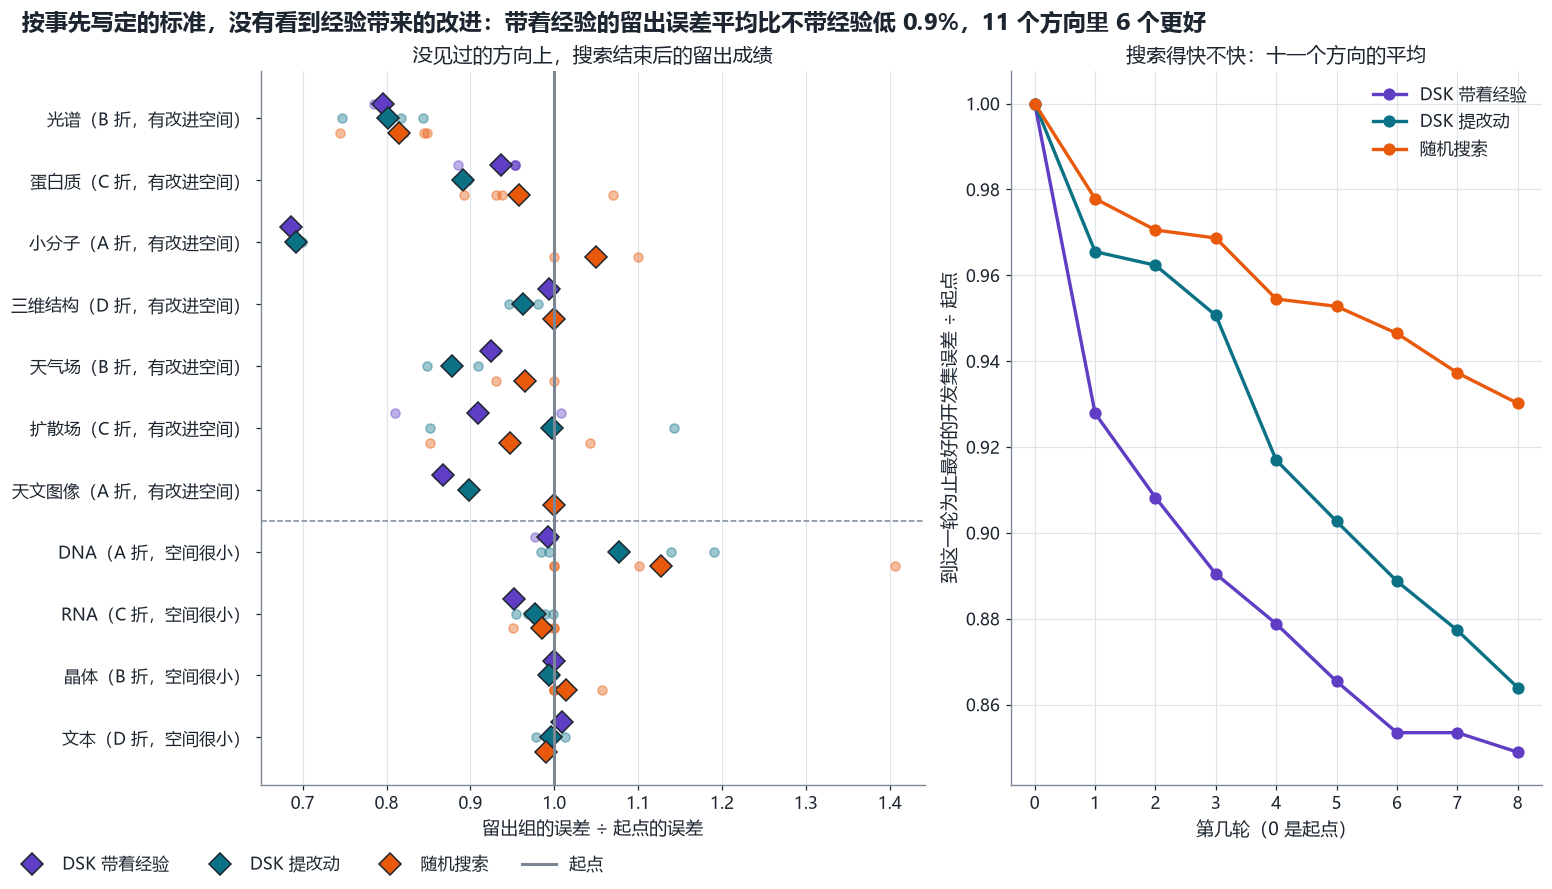

有改进空间的 7 个方向：带经验比不带经验平均低 0.2%，4 个方向更好
改进空间很小的 4 个方向：带经验比不带经验平均低 2.2%，2 个方向更好
和随机搜索比：平均低 7.5%，10 个方向更好，结论：有用


In [12]:
from autoresearch import search_skill

search_plots.show_skill_transfer()

下面打印当前方向用到的那份经验。写它的时候，DSK 没有见过这个方向的任何记录。

扩散场在 C 折，这一折留出的方向：蛋白质、扩散场、RNA
按输入类型与起点读出方式决定前几轮：符号序列（DNA、小分子、文本）若起点是 probe，先试 readout=finetune（小分子 2/2 有效，0.76/0.59；DNA 起点已是 finetune 故无此证据；文本起点 finetune 改 probe 有害 1.35）。若起点已是 finetune，符号序列优先试 objective=masked、mask_ratio=0.3（DNA 2/2 有效，0.83/0.83；小分子 2/2 有效，0.65/0.65；文本 1/2 有效，另一次 1.04），并配 finetune_lr=0.0003（DNA 2/2，0.80/0.81；小分子 1/1 无效 0.83；文本 2/2 有效，0.96/0.95）。数值块序列（光谱、三维结构、天气、天文）若起点 probe：光谱先试 readout=finetune（2/2，0.79/0.79），再叠 pretrain_lr=0.003（1/1，0.77）；天气先试 masked+pretrain_lr=0.003（2/2，0.95/0.95）再调 ridge_alpha=10（2/2，0.82/0.85）；天文先试 ridge_alpha=10（1/1，0.95）或 masked+finetune+finetune_lr=0.0003（2/2，0.93/0.93）；三维结构 masked 略好（2/2，0.96/0.94）但幅度小。晶胞起点 finetune：只试 finetune_steps=400（2/2，0.995/0.995），几乎无改进，其余多有损。通用有害项：merge=2 在多数方向无益或有害（光谱 1.03、DNA 0.94、小分子 1.05、天气 1.13、天文 1.29、文本 0.97；仅光谱与随机搜索偶有 0.75 但伴随其他改动），不要早试；pool=last 常有害（DNA 1.10、小分子 1.59、天气 1.64、天文 2.02、文本 1.30），避免；objective=skip 普遍差（DNA 1.02、小分子 1.30、天气 1.07、天文 1.35、三维 1.31），不优先；pretrain_steps 减半或四分之一多有害（DNA 0.97、小分子 1.42、天气 0.

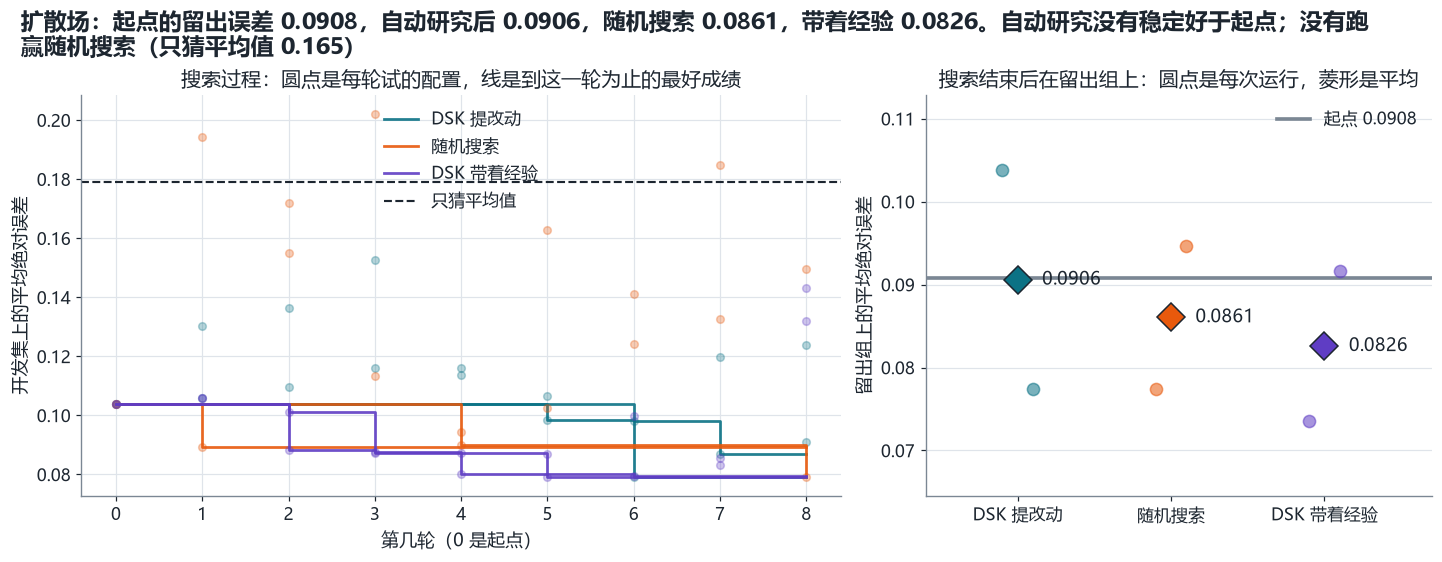

DSK 提改动 第 1 次：选中第 7 轮，留出误差 0.1038，相对起点改了 {"merge": 2, "objective": "masked", "pretrain_steps": 1600}
DSK 提改动 第 2 次：选中第 6 轮，留出误差 0.07743，相对起点改了 {"merge": 2, "finetune_steps": 400, "finetune_lr": 0.0003}
随机搜索 第 1 次：选中第 8 轮，留出误差 0.07743，相对起点改了 {"merge": 2, "finetune_steps": 400, "finetune_lr": 0.0003}
随机搜索 第 2 次：选中第 1 轮，留出误差 0.09468，相对起点改了 {"objective": "masked", "pretrain_lr": 0.003, "finetune_steps": 100, "pretrain_steps": 3200}
DSK 带着经验 第 1 次：选中第 6 轮，留出误差 0.0736，相对起点改了 {"merge": 2, "pretrain_lr": 0.003, "finetune_lr": 0.0003}
DSK 带着经验 第 2 次：选中第 5 轮，留出误差 0.09159，相对起点改了 {"objective": "masked", "mask_ratio": 0.3, "pretrain_lr": 0.003, "finetune_steps": 400, "finetune_lr": 0.0003, "pretrain_steps": 3200}


In [13]:
print(f"{spec['name']}在 {search_skill.fold_of(FIELD)} 折，这一折留出的方向："
      + "、".join(eleven.FIELDS[field]["name"] for field in search_skill.FOLDS[search_skill.fold_of(FIELD)]))
print(search_skill.locked(FIELD))
search_plots.show_search(FIELD, search.archived(FIELD))

## 8. 星流轨道拟合：调参智能体怎样积累经验

上一节的程序每次都从零开始，上一次搜索学到的东西不会留给下一次。这一节换一个任务，看“把经验留下来”是什么样子。

任务是拟合银河系里一条恒星流（GD-1）的轨道：给定一组观测，调 7 个参数，让算出来的轨道穿过观测点。智能体是 DSK，一次拟合只能试 40 组参数。实验分两层：

- **一次拟合之内**：DSK 每交 10 组参数，看到拟合得好不好，再交下一批。
- **多次拟合之间**：DSK 把调参心得写成一份一千多字的经验。每轮先带着经验拟合两个训练场景，对照答案改写经验，然后锁定，拿去拟合 8 个从没见过的场景。共 8 轮。

这一节的图全部来自存档的参数，轨道在你的电脑上重新积分，不需要密钥。先看一个没见过的场景：每一轮的经验各拟合一次，找到的最好轨道叠在观测点上。

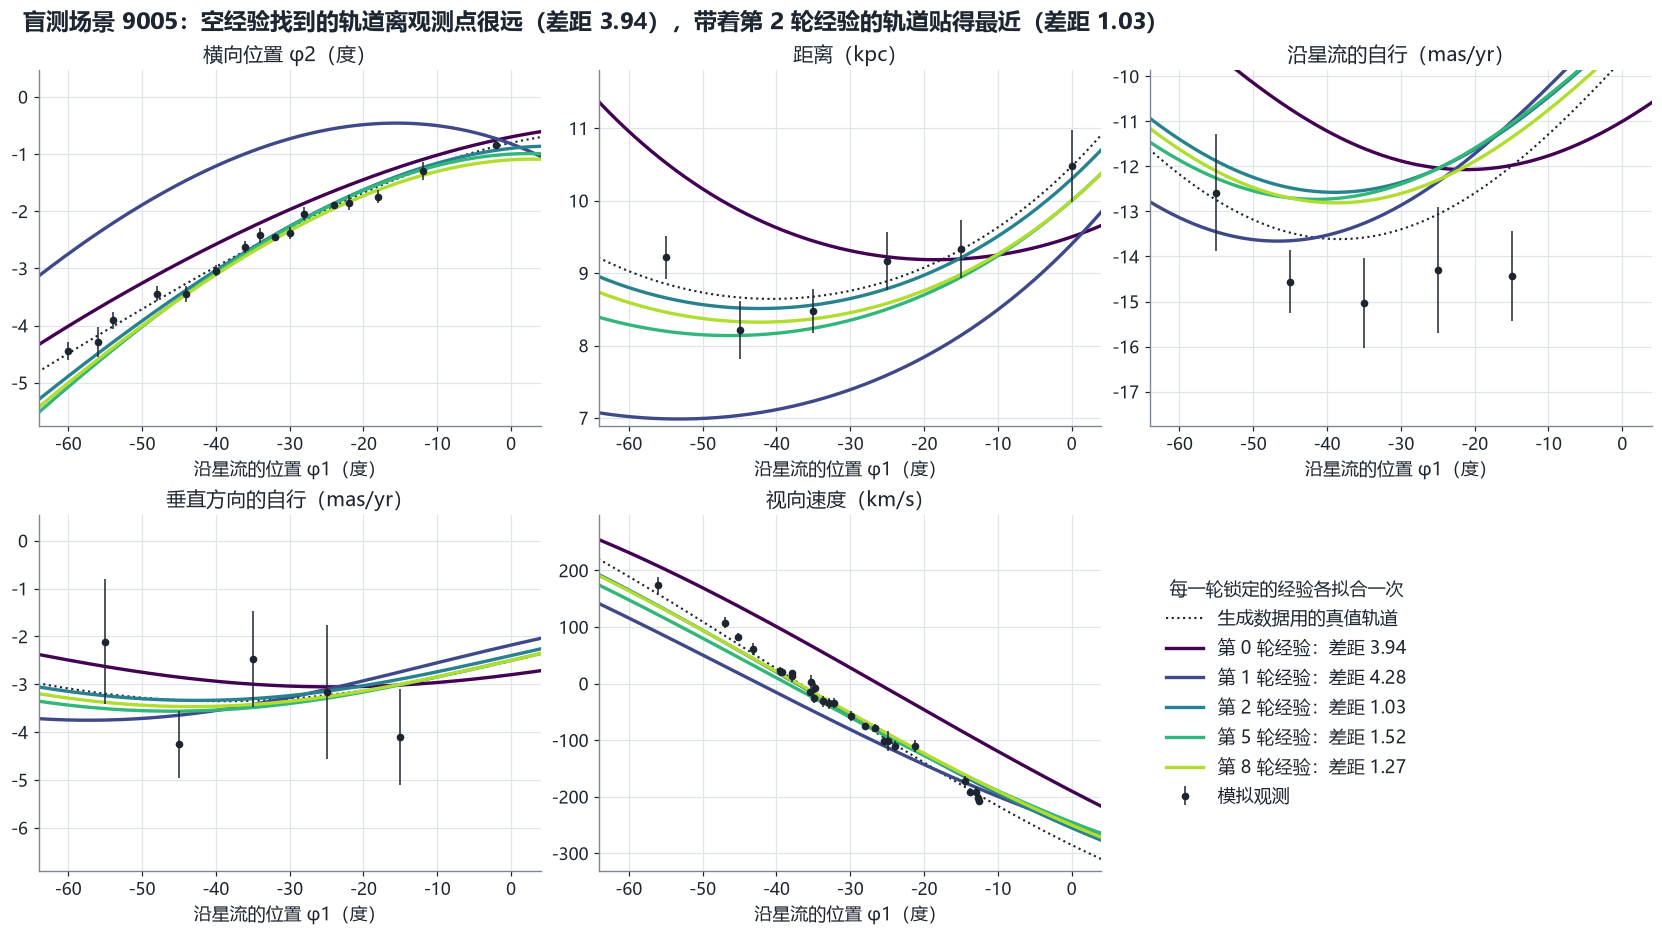

In [14]:
SCENARIO = 9005            # 盲测场景，可选 9001 到 9008
SHOW_ROUNDS = (0, 1, 2, 5, 8)   # 画哪几轮的经验。0 是空经验

from autoresearch import stream_plots

stream_plots.show_orbits(SCENARIO, SHOW_ROUNDS)

一次拟合之内发生了什么：上排是空经验，下排是第 8 轮的经验，颜色从深到浅是第 1 到第 4 次提交之后的最好轨道。

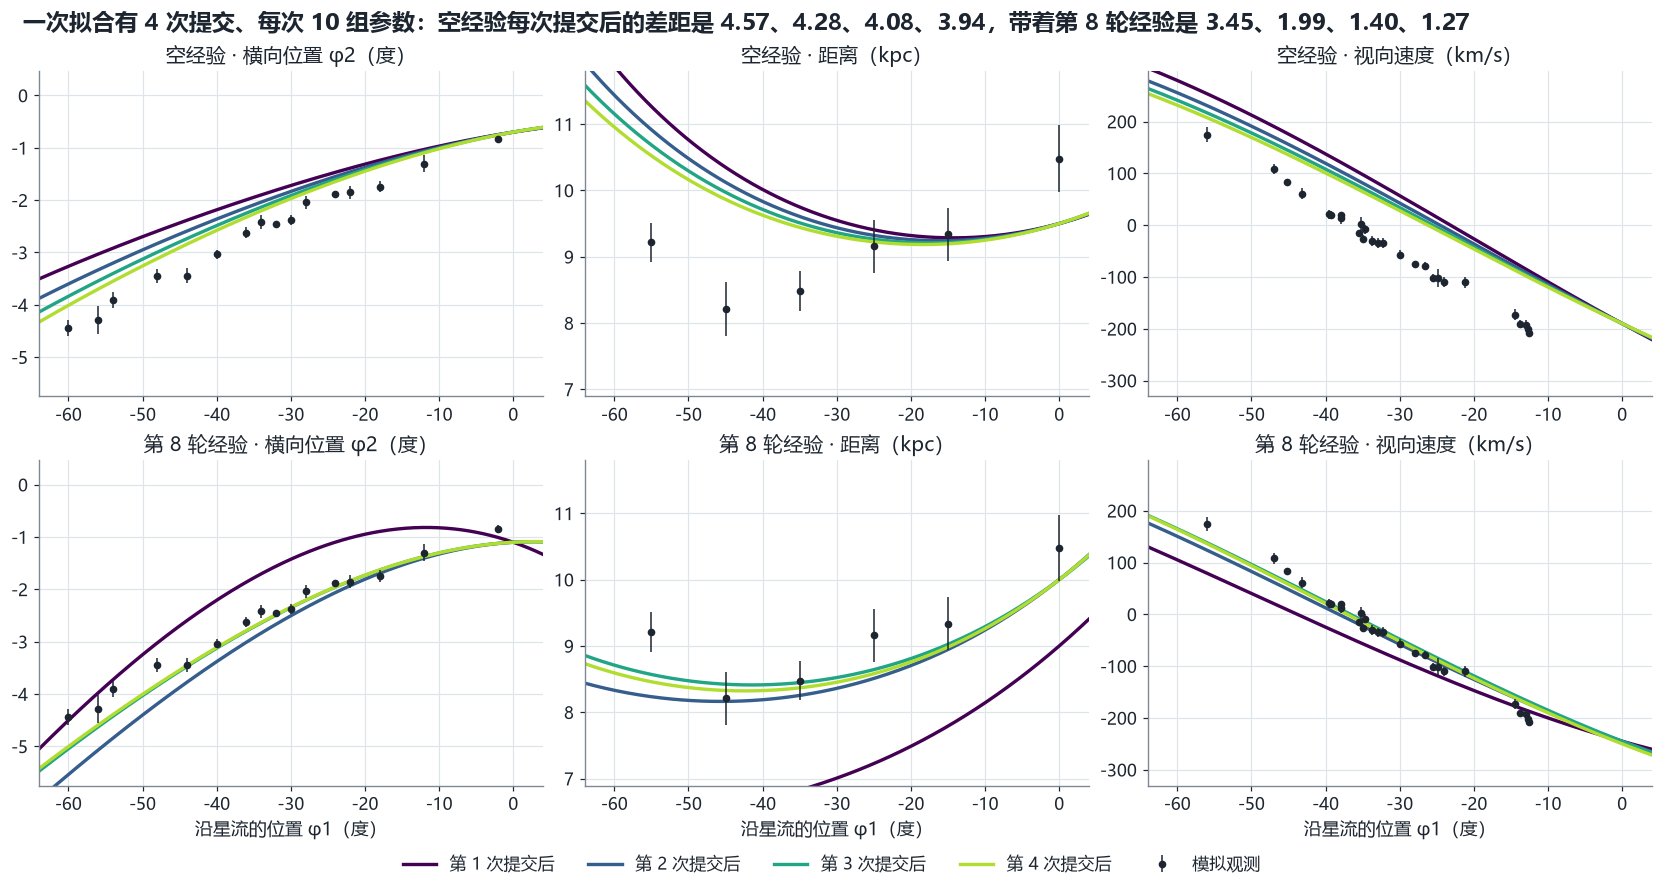

In [15]:
stream_plots.show_one_fit(SCENARIO, rounds=(0, 8))

经验是怎么被改写的。

- 第一张图：九条有代表性的规则，在每一轮的经验里有没有。能看到有的规则一开始就有并一直留着，有的被证据推翻后删掉（“围绕一个中心点撒点”），有的后来才加进来。
- 第二张图：经验的长度、每次改写保留了上一轮多少文字、每一轮的规则注明依据的是哪几轮的训练场景。

图下面是 DSK 自己写的每轮改动说明。想读某一轮经验的全文，把 `READ_ROUND` 改成那一轮的编号。

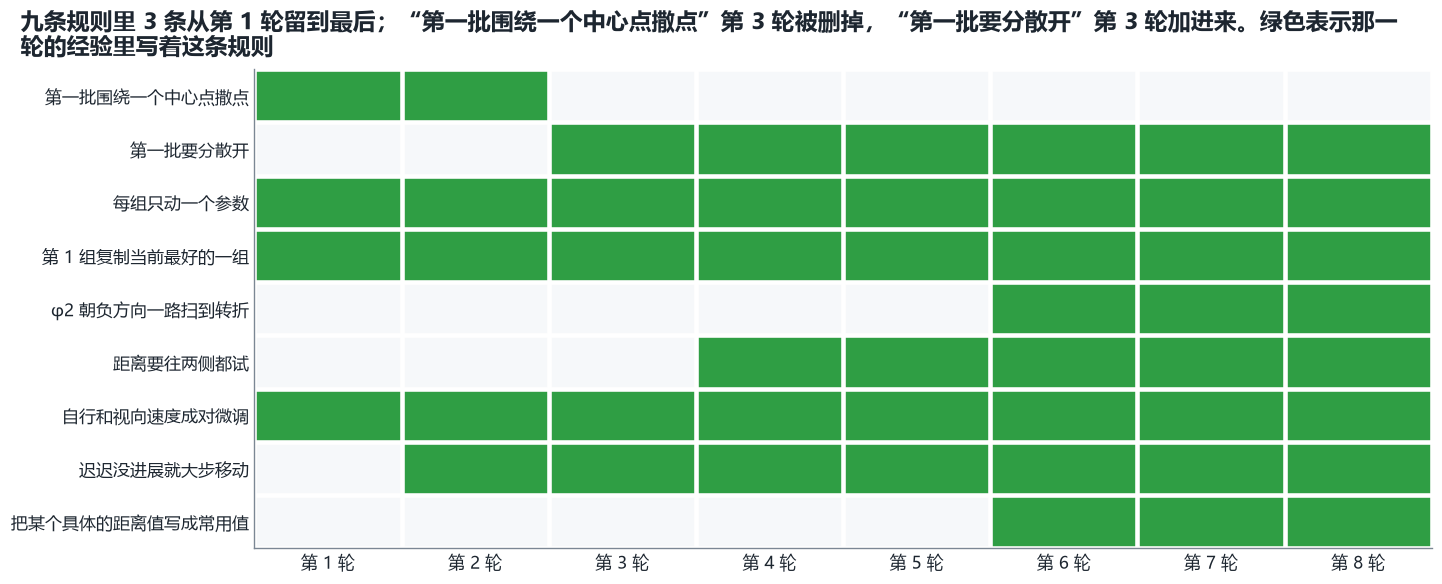

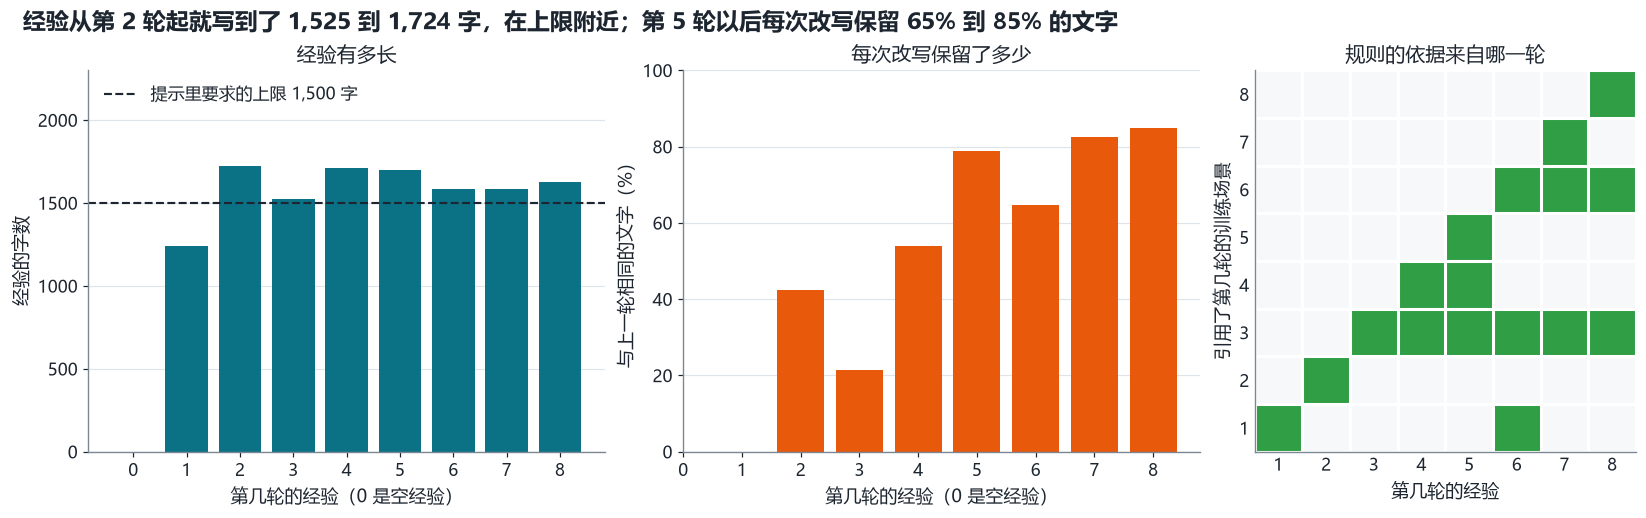

第 1 轮改了什么：旧版无经验；新版基于场景101和102的逐组证据，新增初值定位、首轮10组分配、参数敏感度排序、每轮10组规则、接受准则、vlos-pmphi1耦合、次优盆地逃逸和边界检查等可执行规则，并删去未经验证的大范围拉丁超立建议。

第 2 轮改了什么：旧版假设GD-1量级中心[210,0.9,-0.8,9,-8.5,-2,-250]并称首轮密集撒点有效，但201/202证据显示该中心首轮χ²均>1e4且输/仅小赢随机搜索，故改为按观测χ²反推初值并给出更接近真值的中心[220,0.9,-0.9,9.5,-9,-2.4,-255]。旧版称pmphi……

第 3 轮改了什么：相对旧版：1) 删除“用中心[220,0.9,-0.9,9.5,-9,-2.4,-255]附近撒点”作为首选，因301/302首轮该中心χ²>3.6e4/1.1e5且全轮未达随机水平；2) 强化“phi2小步扫描无改善时立即跳经验真值区”规则，依据301 #0-#3、302 #0-#3 phi2几乎……

第 4 轮改了什么：1) 保留初值定位的分散探索原则，但用401/402证据替换301/302的固定中心失败案例；2) 每轮分配改为有401/402具体组号支撑的规则，pmphi2改为两侧都试（402 #24 -2.6改善而#23 -2.4恶化，旧版只说偏离0.1恶化）；3) dist步长规则改为依场景两侧扫描（401……

第 5 轮改了什么：1) 首轮定位：补充vlos在502首轮占主导的证据（502 #0 vlos=1089），强调vlos也是首轮主导残差之一。2) phi2方向：由旧版'两侧都试'改为'通常向更负方向改善'，依据501 #31/#39、502 #21。3) pmphi2：由旧版'方向依场景而定'改为'偏离0.1即恶化……

第 6 轮改了什么：保留有证据的骨架与单参数小步规则；修正phi2规则为连续向负扫到转折（602#31/#32证据）；确认pmphi2偏离即恶化（601/602一致）；确认dist两侧扫描且9.5常优；确认pmphi1/vlos成对微调收益低（601#38、602#38均恶化）；新增vc/q小步可微调（601#39、6……

第 7 轮改了什么：相对旧版：1) 补充701/702证据，更新各参数步长与方向的依据；2) 明确phi2向负扫到

In [16]:
READ_ROUND = None          # 填 1 到 8 的数字，打印那一轮经验的全文

stream_plots.show_skill_changes()
if READ_ROUND:
    print(stream_plots.skill_text(READ_ROUND))

最后看成绩。纵轴是在没见过的场景上，找到的最好轨道离答案还有多远，越低越好。

读这张图要注意三件事：带着经验比空经验好；最好的是第 5 轮，之后三轮又慢慢变差，没有一轮比一轮好下去；和同样预算的 Nelder–Mead（一种不用模型的经典优化方法）相比，优势不明显。经验的完整文本、实验规则和后续复验见仓库的 docs/stream-skill.md。

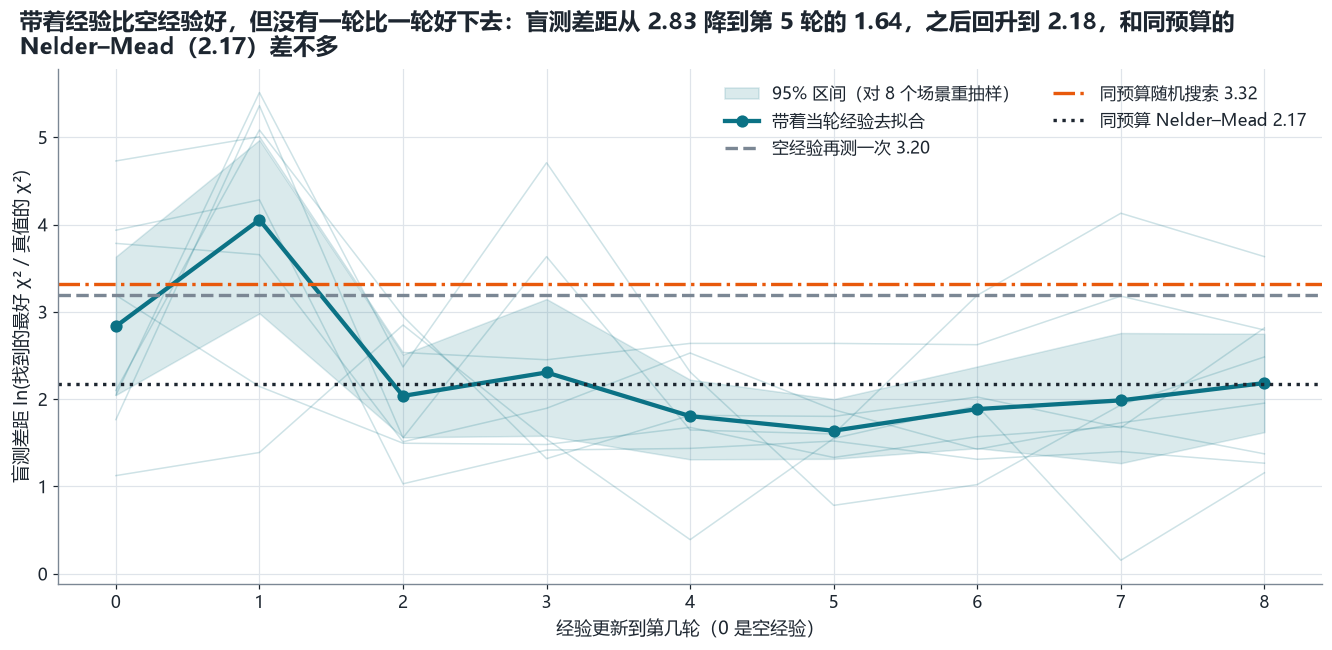

In [17]:
stream_plots.show_blind_scores()

## 接下来可以做什么

- 回到第 0 节换一个 `FIELD`，从头再跑一遍，比较两个方向的图。
- 第 0 节把 `N_LABELS` 改成 8 或 128，从头再跑：标签更少时，预训练的帮助是更大还是更小？
- 第 5 节换一种 `READOUT`：冻结主干和全参数微调，哪一种在这个方向上更好？
- 第 7 节把 `ROUNDS` 和 `DEV_SEEDS` 调到存档的设置，看你的随机搜索和存档里的差多少。
- 命令行里做同样的事：`python -m nanoscigpt.tasks.eleven --field field` 和 `python -m autoresearch.common_search --field field --method random`。